# Custom CNN comparison: Model A versus Model B

EN3150 Assignment 03, task 4. Compare the completed standard CNN and lightweight depthwise-separable CNN using **saved results only**. This notebook does not load models, train networks or run test inference.

Run from the repository root after `ModelA.ipynb` and `ModelB.ipynb` have exported their final results. The primary evidence is `results/model_a.json` and `results/model_b.json`. Missing results stop execution with an actionable message; no illustrative values are substituted.

Both models must use the shared EuroSAT 64x64 RGB split. Parameter and MAC reductions measure architectural cost; epoch time is conditional on hardware, runtime, batch size and data loading. Keras file sizes include format overhead and exclude optimizer state under the model notebooks' export convention.


In [2]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")
SPLIT_CSV = Path("data/eurosat_split.csv")
EXPECTED_CLASSES = [
    "AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
    "Pasture", "PermanentCrop", "Residential", "River", "SeaLake",
]
REQUIRED = ["model", "total_params", "trainable_params", "macs", "size_kb", "size_mb",
            "epochs", "time_per_epoch_s", "test_accuracy", "precision_macro", "recall_macro",
            "f1_macro", "class_names", "confusion_matrix", "history"]


def load_result(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Complete the corresponding model's training and test export first.")
    result = json.loads(path.read_text(encoding="utf-8"))
    missing = [key for key in REQUIRED if key not in result]
    if missing:
        raise ValueError(f"Missing result fields in {path}: {missing}")
    if result.get("smoke", False):
        raise ValueError("Smoke results cannot be compared as final results")
    assert result["class_names"] == EXPECTED_CLASSES, f"Unexpected class order: {path}"
    for key in ["total_params", "trainable_params", "macs", "size_kb", "size_mb", "time_per_epoch_s"]:
        assert np.isfinite(result[key]) and result[key] > 0, f"Invalid {key}: {path}"
    assert result["total_params"] >= result["trainable_params"]
    assert result["epochs"] >= 20, "Assignment requires at least 20 epochs"
    for key in ["test_accuracy", "precision_macro", "recall_macro", "f1_macro"]:
        assert np.isfinite(result[key]) and 0 <= result[key] <= 1, f"Invalid {key}: {path}"
    np.testing.assert_allclose(result["size_mb"], result["size_kb"] / 1024, rtol=0, atol=0.001)
    cm = np.asarray(result["confusion_matrix"])
    assert cm.shape == (10, 10) and np.issubdtype(cm.dtype, np.integer) and (cm >= 0).all()
    assert int(cm.sum()) == 4050, "Expected 4,050 test images"
    np.testing.assert_allclose(np.trace(cm) / cm.sum(), result["test_accuracy"], rtol=0, atol=0.0005)
    for key in ["loss", "accuracy", "val_loss", "val_accuracy"]:
        values = result["history"][key]
        assert len(values) == result["epochs"] and np.isfinite(values).all(), f"Invalid history: {key}"
    if result.get("split_sha256"):
        assert result["split_sha256"] == hashlib.sha256(SPLIT_CSV.read_bytes()).hexdigest(), "Split hash differs"
    return result


model_a = load_result(RESULTS_DIR / "model_a.json")
model_b = load_result(RESULTS_DIR / "model_b.json")
assert model_b["trainable_params"] <= 100_000, "Model B exceeds its trainable parameter budget"
np.testing.assert_array_equal(np.asarray(model_a["confusion_matrix"]).sum(axis=1),
                              np.asarray(model_b["confusion_matrix"]).sum(axis=1))


## 1. Experimental context

Check this table before interpreting training time. Matching a generic device label such as CPU does not establish matching hardware. If a result lacks a split hash, matching class counts supports consistency but cannot prove that the exact test images were identical; consult the model notebook and committed split.


In [3]:
context = pd.DataFrame([
    {"model": r["model"], "epochs": r["epochs"], "batch_size": r.get("batch_size", "not recorded"),
     "device": str(r.get("device", "not recorded")), "split_hash_recorded": bool(r.get("split_sha256")),
     "optimizer": r.get("optimizer", "not recorded"), "initial_lr": r.get("learning_rate", "not recorded")}
    for r in [model_a, model_b]
])
display(context)
print("Epoch times are descriptive. Verify matching hardware/runtime and batch size before claiming a speedup.")
if not all(r.get("split_sha256") for r in [model_a, model_b]):
    print("Exact split provenance is not recorded in both files; verify the shared split from the source notebooks.")


,model,epochs,batch_size,device,split_hash_recorded,optimizer,initial_lr
0,Model A,40,128,CPU,False,Adam,0.003
1,Model B,40,16,['/physical_device:CPU:0'],True,Adam,0.003


Epoch times are descriptive. Verify matching hardware/runtime and batch size before claiming a speedup.
Exact split provenance is not recorded in both files; verify the shared split from the source notebooks.


## 2. Required comparison table and cost plots

File sizes use the repository's convention: KB = bytes/1024. MACs count convolution/dense operations per 64x64 image; other operations and memory traffic are excluded. Test accuracy differences are descriptive single-run results, without a statistical significance claim.


,total_params,trainable_params,macs,size_kb,time_per_epoch_s,test_accuracy,precision_macro,recall_macro,f1_macro
model,,,,,,,,,
Model A,424042,423082,60196096,1729.800000,85.550000,0.962000,0.961000,0.960400,0.960600
Model B,81253,80293,7345408,393.399414,133.051882,0.953333,0.952244,0.951733,0.951912


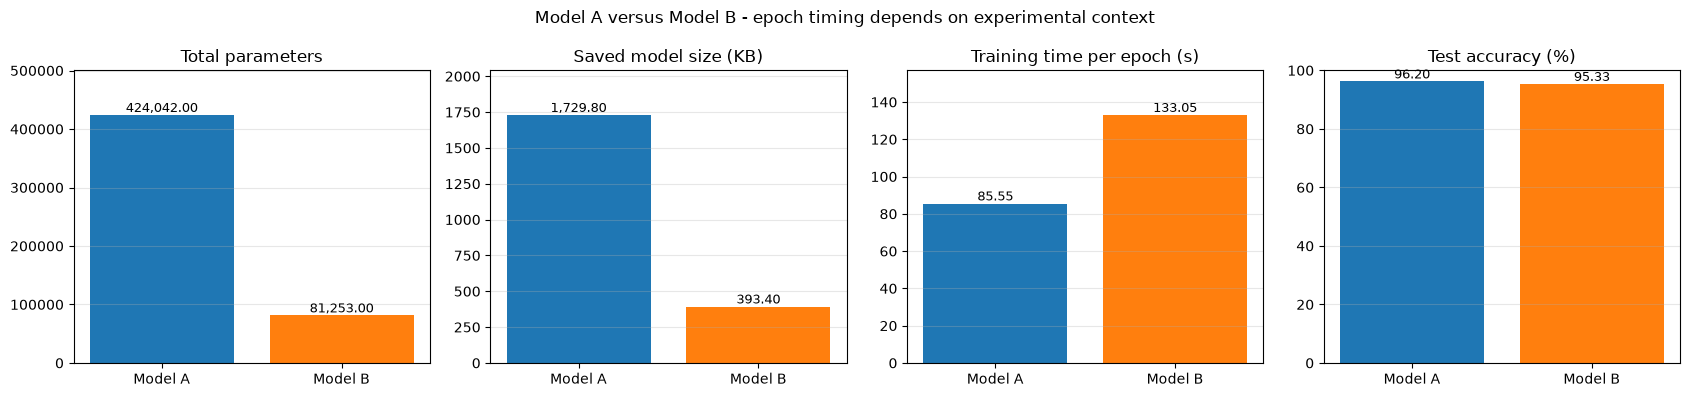

In [4]:
comparison = pd.DataFrame([
    {"model": r["model"], "total_params": r["total_params"], "trainable_params": r["trainable_params"],
     "macs": r["macs"], "size_kb": r["size_kb"], "time_per_epoch_s": r["time_per_epoch_s"],
     "test_accuracy": r["test_accuracy"], "precision_macro": r["precision_macro"],
     "recall_macro": r["recall_macro"], "f1_macro": r["f1_macro"]}
    for r in [model_a, model_b]
]).set_index("model")
comparison.to_csv(RESULTS_DIR / "compare_ab.csv")
display(comparison)
FIGURES_DIR.mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for axis, key, title, scale in zip(
    axes, ["total_params", "size_kb", "time_per_epoch_s", "test_accuracy"],
    ["Total parameters", "Saved model size (KB)", "Training time per epoch (s)", "Test accuracy (%)"],
    [1, 1, 1, 100],
):
    values = comparison[key].to_numpy() * scale
    axis.bar(comparison.index, values, color=["#1f77b4", "#ff7f0e"])
    axis.set_title(title); axis.grid(axis="y", alpha=0.3)
    axis.set_ylim(0, 100 if key == "test_accuracy" else max(values) * 1.18)
    for i, value in enumerate(values):
        axis.text(i, value, f"{value:,.2f}", ha="center", va="bottom", fontsize=9)
fig.suptitle("Model A versus Model B - epoch timing depends on experimental context")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "compare_AB.png", dpi=150)
plt.show(); plt.close(fig)


In [5]:
parameter_reduction = 100 * (1 - model_b["total_params"] / model_a["total_params"])
mac_reduction = 100 * (1 - model_b["macs"] / model_a["macs"])
size_reduction = 100 * (1 - model_b["size_kb"] / model_a["size_kb"])
accuracy_difference = 100 * (model_b["test_accuracy"] - model_a["test_accuracy"])
summary = f"""Model B uses **{model_b['trainable_params']:,} trainable parameters**, within the 100,000 limit.
Relative to Model A, its total parameter count changes by **{-parameter_reduction:+.2f}%**, its MAC count by
**{-mac_reduction:+.2f}%**, and saved file size by **{-size_reduction:+.2f}%**.
Its test accuracy differs by **{accuracy_difference:+.2f} percentage points**.

Reported epoch times are **{model_a['time_per_epoch_s']:.2f} s** for Model A and
**{model_b['time_per_epoch_s']:.2f} s** for Model B. Interpret them with the context above; these are training
measurements, not edge-device inference latency.
"""
display(Markdown(summary))


Model B uses **80,293 trainable parameters**, within the 100,000 limit.
Relative to Model A, its total parameter count changes by **-80.84%**, its MAC count by
**-87.80%**, and saved file size by **-77.26%**.
Its test accuracy differs by **-0.87 percentage points**.

Reported epoch times are **85.55 s** for Model A and
**133.05 s** for Model B. Interpret them with the context above; these are training
measurements, not edge-device inference latency.


## 3. Report discussion to complete from the real results

- Explain depthwise spatial filtering followed by pointwise channel mixing, and relate the parameter/MAC differences to the formulas in `ModelB.ipynb`.
- Interpret the measured accuracy difference alongside class-specific precision, recall and confusion matrices. Do not assume the lighter model must be less accurate.
- Separate raw weight storage and Keras file overhead from runtime activation memory. A smaller model file alone does not prove it fits a particular microcontroller.
- Describe whether measured epoch time follows the MAC reduction. Memory traffic, operator implementation, hardware and pipeline differences can affect timing.
- Explain whether the observed accuracy/cost balance suits the target application. No minimum accuracy is specified in the brief, and no fabricated target-device measurements should be added.

The generated table and summary support the report but do not replace interpretation. Comparison with pretrained lightweight models belongs to a later group workstream, once their results are available.
